# ALL THIS NOTEBOOK IS JUST ABOUT SAMPLING
- DDPM,DDIM,etc...(but we use the same model we trained)

# Setup

In [1]:
import sys
sys.path.insert(0, '/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/fast_ai/Part_2/course22p2')
import pickle,gzip,math,os,time,shutil,torch,random,logging
import fastcore.all as fc,matplotlib as mpl,numpy as np,matplotlib.pyplot as plt
from collections.abc import Mapping
from pathlib import Path
from functools import partial

from fastcore.foundation import L
import torchvision.transforms.functional as TF,torch.nn.functional as F
from torch import tensor,nn,optim
from torch.utils.data import DataLoader,default_collate
from torch.nn import init
from torch.optim import lr_scheduler

from miniai.datasets import *
from miniai.conv import *
from miniai.learner import *
from miniai.activations import *
from miniai.init import *
from miniai.sgd import *
from miniai.resnet import *
from miniai.augment import *
from miniai.accel import *
from miniai.fid import *

from fastprogress.fastprogress import progress_bar
from torcheval.metrics import MulticlassAccuracy
from datasets import load_dataset,load_dataset_builder

mpl.rcParams['image.cmap'] = 'gray_r'
logging.disable(logging.WARNING)

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [2]:
xl,yl = 'image','label'
name = "fashion_mnist"
dsd = load_dataset(name)

In [3]:
from diffusers import UNet2DModel, DDIMPipeline, DDPMPipeline, DDIMScheduler, DDPMScheduler

# Diffusers DDPM sched

In [4]:
class UNet(UNet2DModel): pass

Because:
- the diffusers library depends on having  Unet. model to be having the normal inference where it gives back the object that have `.sample` to get the model preds
- in our saved trained model -> pickle does NOT save the code -> just saves weights + class name string

--> so we always have to define the class before loading the model (and we made it the default Forward because of diffusers library).

In [5]:
model = torch.load('../models/fashion_ddpm3_25.pkl',weights_only=False).cuda()

In [6]:
sched = DDPMScheduler(beta_end=0.01) # beta_start,beta_end ->  default, 0.02(default)

In [7]:
x_t = torch.randn((32,1,32,32)).cuda()

In [8]:
t = 999
t_batch = torch.full((len(x_t),), t, device=x_t.device, dtype=torch.long)
with torch.no_grad(): noise = model(x_t,t_batch).sample

In [9]:
res = sched.step(noise, t, x_t)

    what sched.step does:
    x_0_hat = ((x_t - b̄_t.sqrt() * ...
    x_t = x_0_hat * ᾱ_t1.sqrt()* ....

In [10]:
res.prev_sample.shape # it is x_t

torch.Size([32, 1, 32, 32])

In [11]:
sz = (2048,1,32,32)

In [16]:
%%time
x_t = torch.randn(sz).cuda()
preds = []

for t in progress_bar(sched.timesteps): # it is 1000 by default
    with torch.no_grad(): noise = model(x_t,t).sample
    x_t = sched.step(noise, t, x_t).prev_sample
    preds.append(x_t.float().cpu())

<div><progress max="1000" value="1000"></progress> 100.00% [1000/1000 24:42&lt;00:00]</div>

CPU times: user 22min 16s, sys: 14.7 s, total: 22min 31s
Wall time: 24min 42s


`noise = model(x_t,t).sample `-> no need for t_batch, Unet takes the scalar t and makes it automatically (broadcasting)

In [17]:
s = preds[-1].clamp(-0.5,0.5)*2

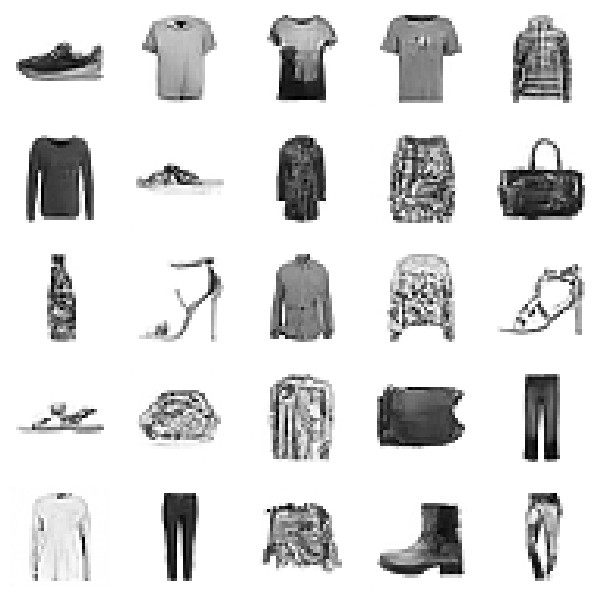

In [18]:
show_images(s[:25], imsize=1.5)

In [12]:
cmodel = torch.load('../models/data_aug2.pkl',weights_only=False)
del(cmodel[8])
del(cmodel[7])

In [13]:
@inplace
def transformi(b): b[xl] = [F.pad(TF.to_tensor(o), (2,2,2,2))*2-1 for o in b[xl]]

bs = 1024
tds = dsd.with_transform(transformi)
dls = DataLoaders.from_dd(tds, bs, num_workers=fc.defaults.cpus)

dt = dls.train
xb,yb = next(iter(dt))

ie = ImageEval(cmodel, dls, cbs=[DeviceCB()])

In [21]:
ie.fid(s),ie.kid(s)

(11.987060546875, 0.2770613729953766)

In [22]:
ie.fid(xb),ie.kid(xb)

(5.62841796875, -0.21872946619987488)

# Diffusers DDIM sched
- see if it is working with existing things, and then make it form scrach

In [14]:
sched = DDIMScheduler(beta_end=0.01)
sched.set_timesteps(333)

In [15]:
def diff_sample(model,sz,sched,**kwargs):
    x_t = torch.randn(sz).cuda()
    preds = []
    for t in progress_bar(sched.timesteps):
        with torch.no_grad(): noise = model(x_t,t).sample
        x_t = sched.step(noise, t, x_t,**kwargs).prev_sample
        if t%10==0 or t<5: preds.append(x_t.float().cpu()) # just for the memory
    return preds

In [16]:
sz = (1024,1,32,32)

In [17]:
preds = diff_sample(model, sz, sched, eta=1.)
s = (preds[-1]*2).clamp(-1,1)

<div><progress max="333" value="333"></progress> 100.00% [333/333 03:39&lt;00:00]</div>

`eta = 1.` is making DDIM same as DDPM,.... [Explainaiton was in the video for the equations]

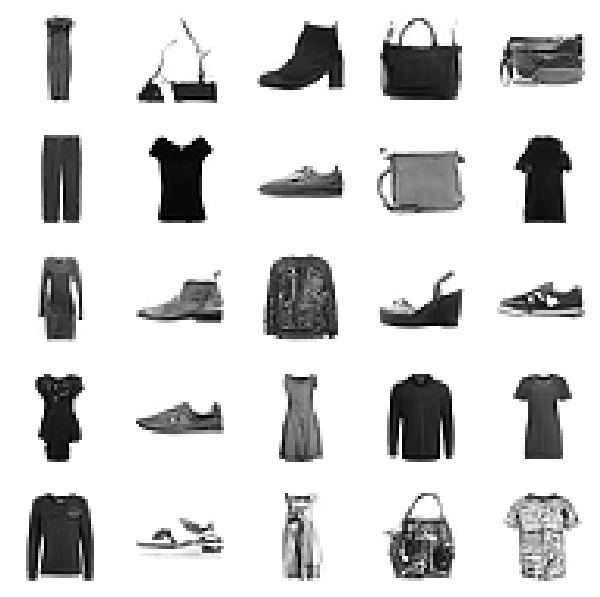

In [18]:
show_images(s[:25], imsize=1.5)

In [21]:
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)}')

(19.2412109375, 0.3048572540283203) 
 (5.388916015625, -0.21738478541374207)


In [22]:
sched.set_timesteps(200)
preds = diff_sample(model, sz, sched, eta=1.)
s = (preds[-1]*2).clamp(-1,1)

<div><progress max="200" value="200"></progress> 100.00% [200/200 02:14&lt;00:00]</div>

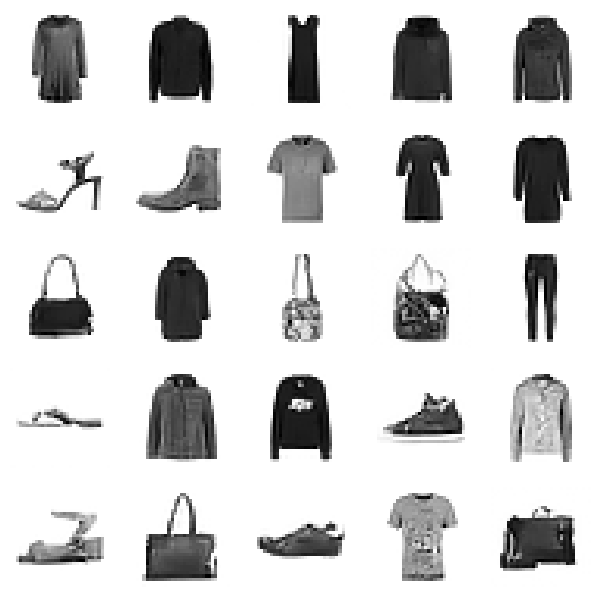

In [23]:
show_images(s[:25], imsize=1.5)

In [24]:
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)}')

(30.233154296875, 0.2467421591281891) 
 (5.388916015625, -0.21738478541374207)


In [25]:
sched.set_timesteps(100)
preds = diff_sample(model, sz, sched, eta=1.)
s = (preds[-1]*2).clamp(-1,1)

<div><progress max="100" value="100"></progress> 100.00% [100/100 01:05&lt;00:00]</div>

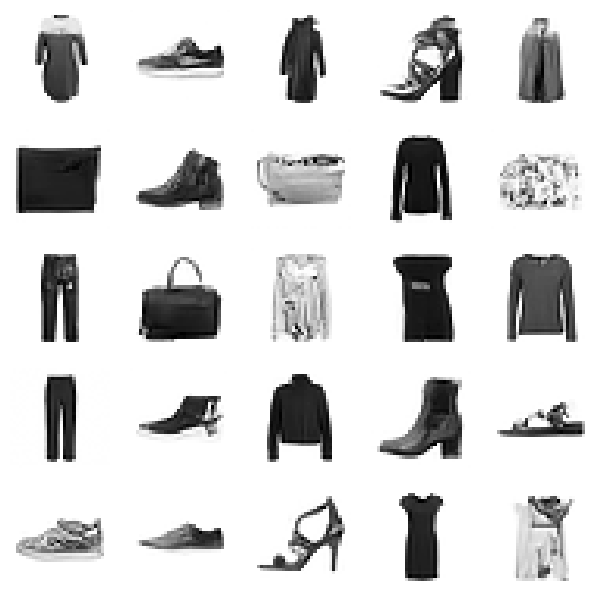

In [26]:
show_images(s[:25], imsize=1.5)

In [27]:
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)}')

(34.300048828125, 0.5062884092330933) 
 (5.388916015625, -0.21738478541374207)


In [28]:
sched.set_timesteps(50)
preds = diff_sample(model, sz, sched, eta=1.)
s = (preds[-1]*2).clamp(-1,1)

<div><progress max="50" value="50"></progress> 100.00% [50/50 00:32&lt;00:00]</div>

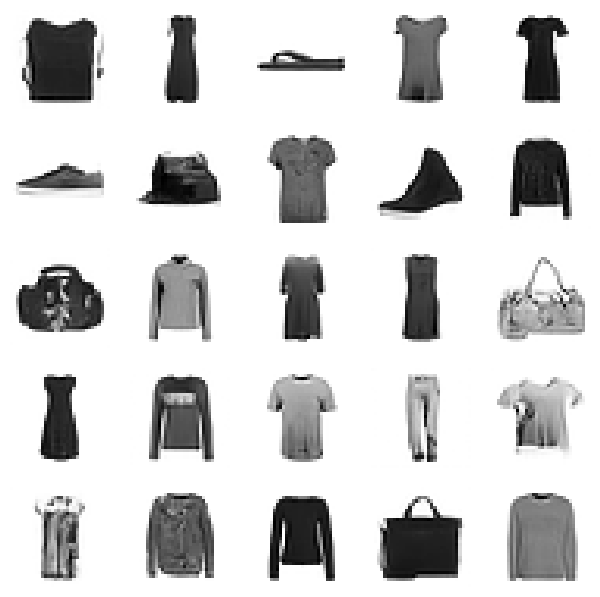

In [29]:
show_images(s[:25], imsize=1.5)

In [30]:
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)}')

(40.674560546875, 0.40315863490104675) 
 (5.388916015625, -0.21738478541374207)


In [31]:
sched.set_timesteps(25)
preds = diff_sample(model, sz, sched, eta=1.)
s = (preds[-1]*2).clamp(-1,1)

<div><progress max="25" value="25"></progress> 100.00% [25/25 00:15&lt;00:00]</div>

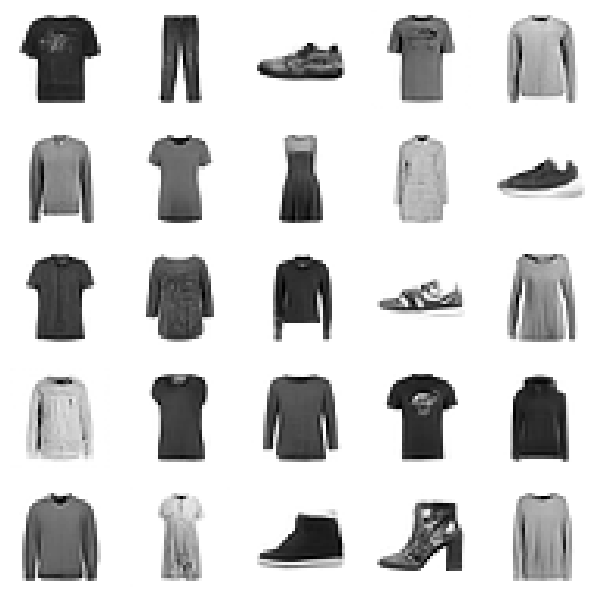

In [32]:
show_images(s[:25], imsize=1.5)

In [33]:
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)}')

(70.98681640625, 1.2382971048355103) 
 (5.388916015625, -0.21738478541374207)


    ─────────────────────────────────────────
    WHY DDPM CANNOT SKIP STEPS
    ─────────────────────────────────────────
    DDPM equation needs beta_t:

    beta_t (individually defined value at each step)
    alpha_t = 1 - beta_t
    alphabar_t = alpha_1 × alpha_2 × ... × alpha_t
                    ↑ cumulative product of ALL previous alphas

    to get alphabar_500:
    you need alpha_1 × alpha_2 × ... × alpha_500
    you MUST go through every single step

    ─────────────────────────────────────────
    DDPM SKIP SAMPLING (what we did before):
    ─────────────────────────────────────────
    still goes through all 1000 update steps
    but only runs model every 3 steps
    t=999, skip, skip, t=996, skip, skip...

    ─────────────────────────────────────────
    DDIM SKIP SAMPLING (this):
    ─────────────────────────────────────────
    literally only 100 steps total
    t=999 → t=900 → t=800...

    to get abar at ANY t:
    just plug t into the formula directly (abar handles the jump correctly)


    - DDPM built everything around beta (beta → alpha → abar)
    lots of variables, hard to jump around

    - DDIM use abar directly
    one variable, compute anywhere, jump anywhere -> cleaner, faster, more flexible ✓

# DDIM (from scrach)

In [17]:
from types import SimpleNamespace

In [18]:
n_steps = 1000

In [19]:
# copy the linear sched
def linear_sched(betamin=0.0001,betamax=0.02,n_steps=1000):
    beta = torch.linspace(betamin, betamax, n_steps)
    return SimpleNamespace(a=1.-beta, abar=(1.-beta).cumprod(dim=0), sig=beta.sqrt())

In [20]:
sc = linear_sched(betamax=0.01, n_steps=n_steps)
abar = sc.abar

In [21]:
list(reversed(range(0, 10, 3)))

[9, 6, 3, 0]

In [22]:
@torch.no_grad()
def sample(f, model, sz, n_steps, skips=1, eta=1.):
    tsteps = list(reversed(range(0, n_steps, skips)))
    x_t = torch.randn(sz).cuda()
    preds = []
    for i,t in enumerate(progress_bar(tsteps)):
        abar_t1 = abar[tsteps[i+1]] if t > 0 else torch.tensor(1)
        noise = model(x_t,t).sample
        x_t = f(x_t, t, noise, abar[t], abar_t1, 1-abar[t], 1-abar_t1, eta)
        preds.append(x_t.float().cpu())
    return preds

![image.png](attachment:d384c1da-8fac-44b6-b94f-acca02e63230.png)

![image.png](attachment:57c69470-25fb-47de-8e4c-7241e8016606.png)

- note that alpha in the DDIM paper is the same as alpha_bar in the DDPM paper
- $\eta$ is eta

In [23]:
# just turn the equation into code
def ddim_step(x_t, t, noise, abar_t, abar_t1, bbar_t, bbar_t1, eta):
    vari = ((bbar_t1/bbar_t) * (1-abar_t/abar_t1))
    sig = vari.sqrt()*eta
    x_0_hat = ((x_t-bbar_t.sqrt()*noise) / abar_t.sqrt())
    x_t = abar_t1.sqrt()*x_0_hat + (bbar_t1-sig**2).sqrt()*noise
    if t>0: x_t += sig * torch.randn(x_t.shape).to(x_t)
    return x_t

`.to(x_t)` is a shorthand that moves the tensor to the same device and dtype as `x_t`.
=`torch.randn(x_t.shape).to(device=x_t.device, dtype=x_t.dtype)`

In [43]:
%%time
samples = sample(ddim_step, model, sz, 1000, 10)

<div><progress max="100" value="100"></progress> 100.00% [100/100 01:10&lt;00:00]</div>

CPU times: user 1min 10s, sys: 165 ms, total: 1min 10s
Wall time: 1min 10s


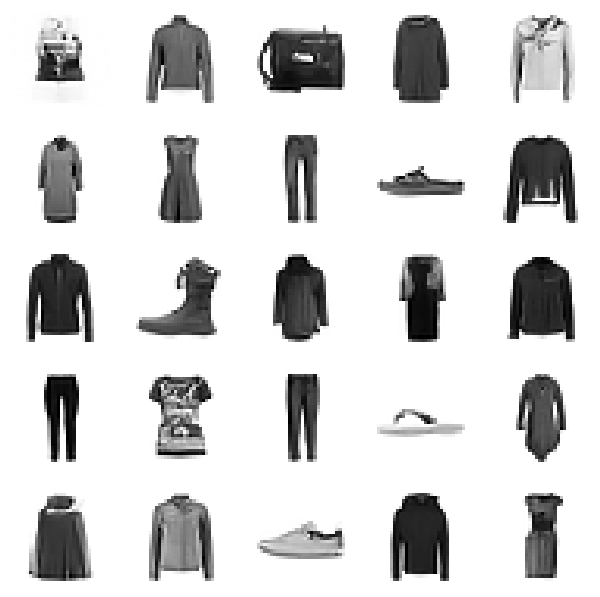

In [44]:
s = (samples[-1] * 2).clamp(-1, 1)
show_images(s[:25], imsize=1.5)

In [45]:
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)}')

(30.2490234375, 0.3756272494792938) 
 (5.388916015625, -0.21738478541374207)


# Triangular noise

In [24]:
def noisify(x0, ᾱ):
    device = x0.device
    n = len(x0)
    # t = torch.randint(0, n_steps, (n,), dtype=torch.long) [previous way]
    t = np.random.triangular(0,0.5,1,(n,))*n_steps
    t = tensor(t,dtype=torch.long)
    ε = torch.randn(x0.shape, device=device)
    ᾱ_t = ᾱ[t].reshape(-1, 1, 1, 1).to(device)
    xt = ᾱ_t.sqrt()*x0 + (1-ᾱ_t).sqrt()*ε
    return (xt, t.to(device)), ε

    Gaussian:              Triangular (this):
         ╭───╮                   /\
        ╭╯   ╰╮                 /  \
    ───╯       ╰───          ──/    \──
      curved edges           straight edges

    np.random.triangular(min, peak, max, shape)

    starts at min (0),
    increases linearly to peak (0.5),
    decreases linearly to max (1)

    gives random float between 0 and 1 → multiply by n_steps
    → float between 0 and 1000

    -> turn into tensor with dtype=torch.long → chop decimal → integer timestep

    WHY?
    - to have middle timesteps (t≈500) get sampled more often during
    training because that is where the model struggles most and
    real learning happens.
    - extremes (t≈0 or t≈999) are easy → less training time wasted
     on them

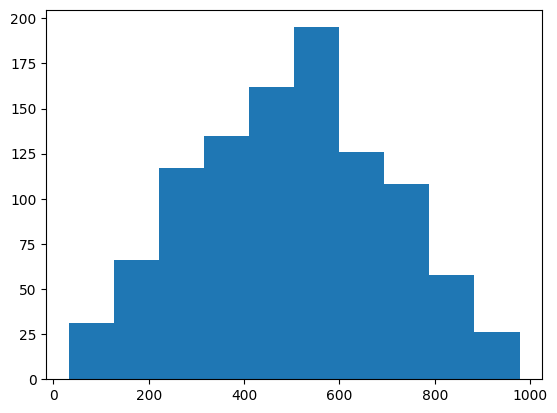

In [47]:
(xt,t),ε = noisify(xb,abar)
plt.hist(t);

# Cosine sched

In [25]:
bs = 256

In [26]:
def abar(t): return (t*math.pi/2).cos()**2 # cos²(t * π/2), t->[0 -> 1]
def inv_abar(abar): return abar.sqrt().acos()*2/math.pi # inverse_fn return t given abar

In [27]:
def noisify(x0):
    device = x0.device
    n = len(x0)
    t = torch.rand(n,).to(x0).clamp(0,0.999) # make 1 -> 0.999
    ε = torch.randn(x0.shape, device=device)
    abar_t = abar(t).reshape(-1, 1, 1, 1).to(device)
    xt = abar_t.sqrt()*x0 + (1-abar_t).sqrt()*ε
    return (xt, t.to(device)), ε

    torch.rand(shape)   → random floats between 0 and 1      (uniform)
    torch.randn(shape)  → random floats centered around 0
                        (mean=0, std=1) (between -3 and 3)

In [28]:
def collate_ddpm(b): return noisify(default_collate(b)[xl])
def dl_ddpm(ds): return DataLoader(ds, batch_size=bs, collate_fn=collate_ddpm, num_workers=4)

In [29]:
@inplace
def transformi(b): b[xl] = [F.pad(TF.to_tensor(o), (2,2,2,2))-0.5 for o in b[xl]]

tds = dsd.with_transform(transformi)
dls = DataLoaders(dl_ddpm(tds['train']), dl_ddpm(tds['test']))

dl = dls.train
(xt,t),eps = b = next(iter(dl))

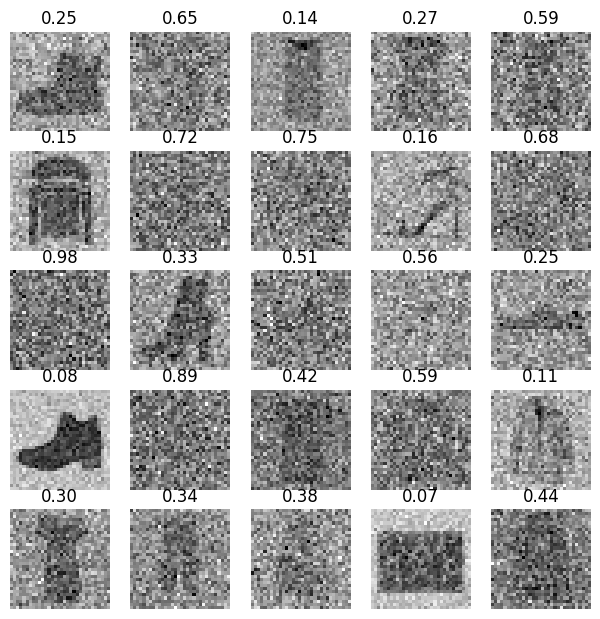

In [30]:
show_images(xt[:25], imsize=1.5, titles=fc.map_ex(t[:25], '{:.02f}'))

In [31]:
class UNet(UNet2DModel):
    def forward(self, x): return super().forward(*x).sample

In [32]:
def init_ddpm(model):
    for o in model.down_blocks:
        for p in o.resnets:
            p.conv2.weight.data.zero_()
            for p in fc.L(o.downsamplers): init.orthogonal_(p.conv.weight)

    for o in model.up_blocks:
        for p in o.resnets: p.conv2.weight.data.zero_()

    model.conv_out.weight.data.zero_()

In [33]:
lr = 4e-3
epochs = 25
opt_func = partial(optim.Adam, eps=1e-5)
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
cbs = [DeviceCB(), MixedPrecision(), ProgressCB(plot=True), MetricsCB(), BatchSchedCB(sched)]
model = UNet(in_channels=1, out_channels=1, block_out_channels=(32, 64, 128, 256), norm_num_groups=8)
init_ddpm(model)
learn = Learner(model, dls, nn.MSELoss(), lr=lr, cbs=cbs, opt_func=opt_func)

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/fast_ai/Part_2/course22p2/miniai/accel.py:33: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  def before_fit(self, learn): self.scaler = torch.cuda.amp.GradScaler()


loss,epoch,train
0.238,0,train
0.054,0,eval
0.049,1,train
0.049,1,eval
0.045,2,train
0.047,2,eval
0.042,3,train
0.042,3,eval
0.040,4,train
0.042,4,eval


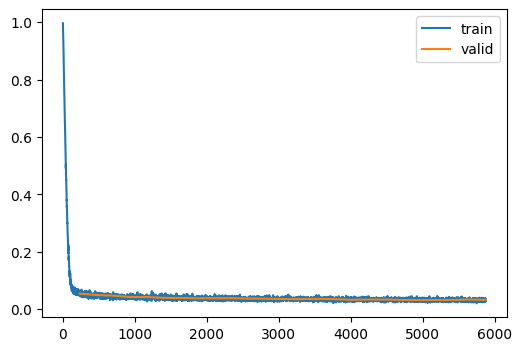

In [34]:
learn.fit(epochs)

In [35]:
# torch.save(learn.model, '../models/fashion_cos.pkl')

In [37]:
def denoise(x_t, noise, t):
    device = x_t.device
    abar_t = abar(t).reshape(-1, 1, 1, 1).to(device)
    return ((x_t-(1-abar_t).sqrt()*noise) / abar_t.sqrt()).clamp(-1,1)

- it predicts `x_0` (and remember the equation in `return` is the algebric solution for `x_0` in the noisify noising equation)

In [38]:
with torch.no_grad(): noise=learn.model((xt.cuda(),t.cuda()))

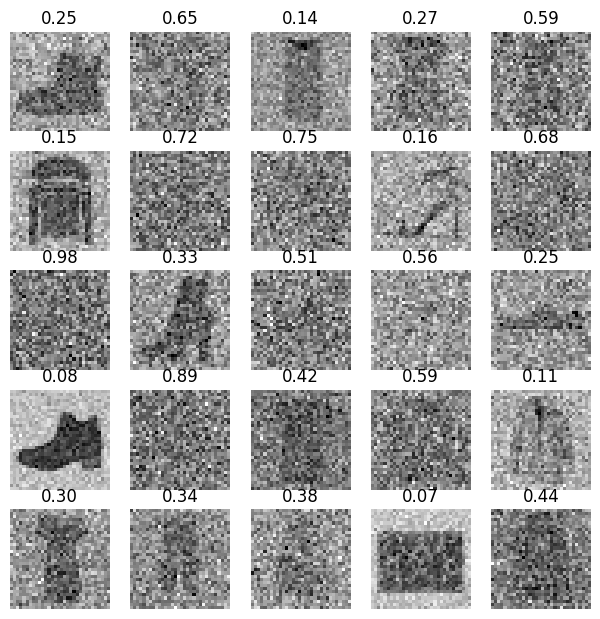

In [39]:
# lets see what is happening
show_images(xt[:25], imsize=1.5, titles=fc.map_ex(t[:25], '{:.02f}'))

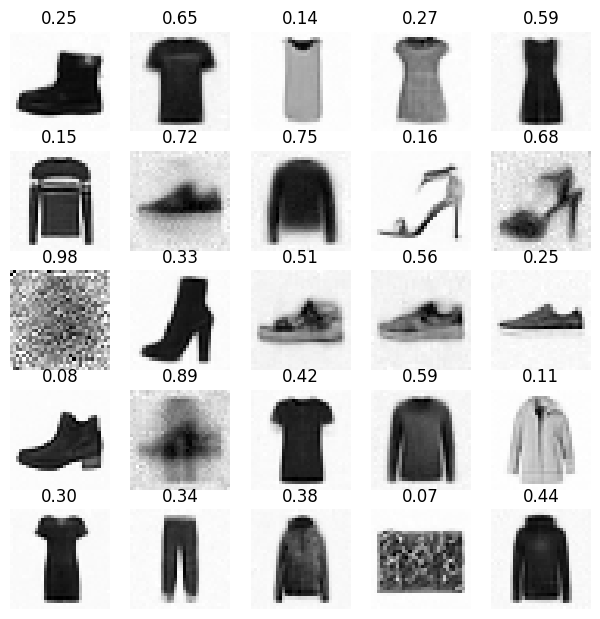

In [40]:
show_images(denoise(xt.cuda(),noise,t.cuda())[:25].clamp(-1,1), imsize=1.5, titles=fc.map_ex(t[:25], '{:.02f}'))

# Sampling

In [41]:
@inplace
def transformi(b): b[xl] = [F.pad(TF.to_tensor(o), (2,2,2,2))*2-1 for o in b[xl]]

bs = 1024
tds = dsd.with_transform(transformi)
dls = DataLoaders.from_dd(tds, bs, num_workers=fc.defaults.cpus)

dt = dls.train
xb,yb = next(iter(dt))

ie = ImageEval(cmodel, dls, cbs=[DeviceCB()])

In [69]:
sz = (1024,1,32,32)

Remember this is sampling with Cosine sched (diff than linear)

In [70]:
@torch.no_grad()
def sample(f, model, sz, n_steps, eta=1.):
    tsteps = torch.linspace(1-1/n_steps,0,n_steps)
    x_t = torch.randn(sz).to(model.device)
    preds = []
    for i, t in enumerate(progress_bar(tsteps)):
        abar_t = abar(t)
        noise = model((x_t, t))
        abar_t1 = abar(t-1/n_steps)  if t>=1/n_steps else torch.tensor(1)
        x_t,x_0_hat = f(x_t, noise, abar_t, abar_t1, 1-abar_t, 1-abar_t1, eta)
        preds.append(x_0_hat.float().cpu())
    return preds

 `preds.append(x_0_hat.float().cpu())` -> this time` append` `x_hat` not `x_t` (more interesting)

In [71]:
# just turn the equation into code
def ddim_step(x_t, noise, abar_t, abar_t1, bbar_t, bbar_t1, eta):
    sig = ((bbar_t1 / bbar_t) * (1 - abar_t / abar_t1)).sqrt() * eta
    x_0_hat = ((x_t - bbar_t.sqrt() * noise) / abar_t.sqrt()).clamp(-1.5,1.5) # SAFETY: clamp
    if bbar_t1<=sig**2+0.01: sig=0. # SAFETY:set to zero if very small or NaN (avoid root -ve)
    x_t = abar_t1.sqrt() * x_0_hat + (bbar_t1 - sig ** 2).sqrt() * noise
    x_t += sig * torch.randn(x_t.shape).to(x_t)
    return x_t,x_0_hat

In [72]:
preds = sample(ddim_step, model, sz, n_steps=100, eta=1.)
s = (preds[-1]*2)
s.min(),s.max(),s.shape

<div><progress max="100" value="100"></progress> 100.00% [100/100 01:08&lt;00:00]</div>

(tensor(-1.0778), tensor(1.3102), torch.Size([1024, 1, 32, 32]))

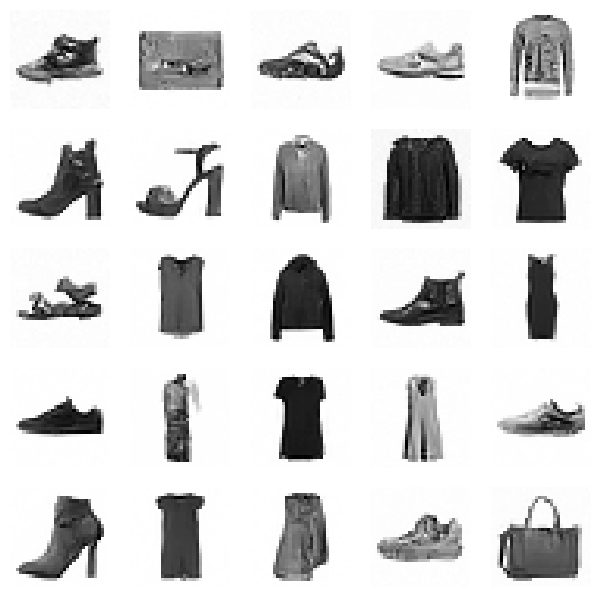

In [73]:
show_images(s[:25], imsize=1.5)

In [74]:
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)}')

(12.56103515625, 0.2126690149307251) 
 (4.901611328125, -0.104811891913414)


In [78]:
preds = sample(ddim_step, model, sz, n_steps=100, eta=1.)
s = (preds[-1]*2)
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)}')

<div><progress max="100" value="100"></progress> 100.00% [100/100 01:07&lt;00:00]</div>

(11.122314453125, -0.09777650237083435) 
 (4.901611328125, -0.104811891913414)


In [79]:
preds = sample(ddim_step, model, sz, n_steps=100, eta=1.)
s = (preds[-1]*2)
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)}')

<div><progress max="100" value="100"></progress> 100.00% [100/100 01:08&lt;00:00]</div>

(14.906982421875, 0.23646219074726105) 
 (4.901611328125, -0.104811891913414)


In [80]:
preds = sample(ddim_step, model, sz, n_steps=200, eta=1.)
s = (preds[-1]*2)
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)}')

<div><progress max="200" value="200"></progress> 100.00% [200/200 02:23&lt;00:00]</div>

(12.1240234375, -0.16127613186836243) 
 (4.901611328125, -0.104811891913414)


In [81]:
preds = sample(ddim_step, model, sz, n_steps=50, eta=1.)
s = (preds[-1]*2)
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)}')

<div><progress max="50" value="50"></progress> 100.00% [50/50 00:34&lt;00:00]</div>

(19.118896484375, 0.5486453175544739) 
 (4.901611328125, -0.104811891913414)


In [82]:
preds = sample(ddim_step, model, sz, n_steps=50, eta=0.5)
s = (preds[-1]*2)
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)}')

<div><progress max="50" value="50"></progress> 100.00% [50/50 00:34&lt;00:00]</div>

(15.066162109375, 0.19813382625579834) 
 (4.901611328125, -0.104811891913414)


In [83]:
preds = sample(ddim_step, model, sz, n_steps=50, eta=0.)
s = (preds[-1]*2)
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)}')

<div><progress max="50" value="50"></progress> 100.00% [50/50 00:34&lt;00:00]</div>

(23.91552734375, 0.18567994236946106) 
 (4.901611328125, -0.104811891913414)
